In [1]:
import matplotlib.pyplot as plt
import numpy as np

from piezolab import Impedance, get_data

plt.style.use('maroon_ipynb.mplstyle')

messy_frequencies, messy_impedance, messy_phase = get_data('messy_sweep_data')
clean_frequencies, clean_impedance, clean_phase = get_data('clean_sweep_data')

messy_obj = Impedance(messy_frequencies, messy_impedance, messy_phase)
clean_obj = Impedance(clean_frequencies, clean_impedance, clean_phase)
messy_obj.curve_fit(off_res_cap=True)
clean_obj.least_squares_fit(resonance_weight=100)

messy_parameter_response = np.abs(messy_obj.equivalent_impedance(1j*messy_obj.angular_frequency))
clean_parameter_response = np.abs(clean_obj.equivalent_impedance(1j*clean_obj.angular_frequency))

# Butterworth Van-Dyke (BVD) Model

The BVD model represents a piezoelectric actuator near a single dominant resonance as an electrical equivalent circuit with two parallel branches:

- **Static capacitance** $C_0$: the clamped dielectric capacitance between the electrodes.
- **Motional branch** $R_1$, $L_1$, $C_1$ in series: the mechanical resonance seen from the terminals. $L_1$ represents the effective mass, $C_1$ the compliance, and $R_1$ the mechanical losses.

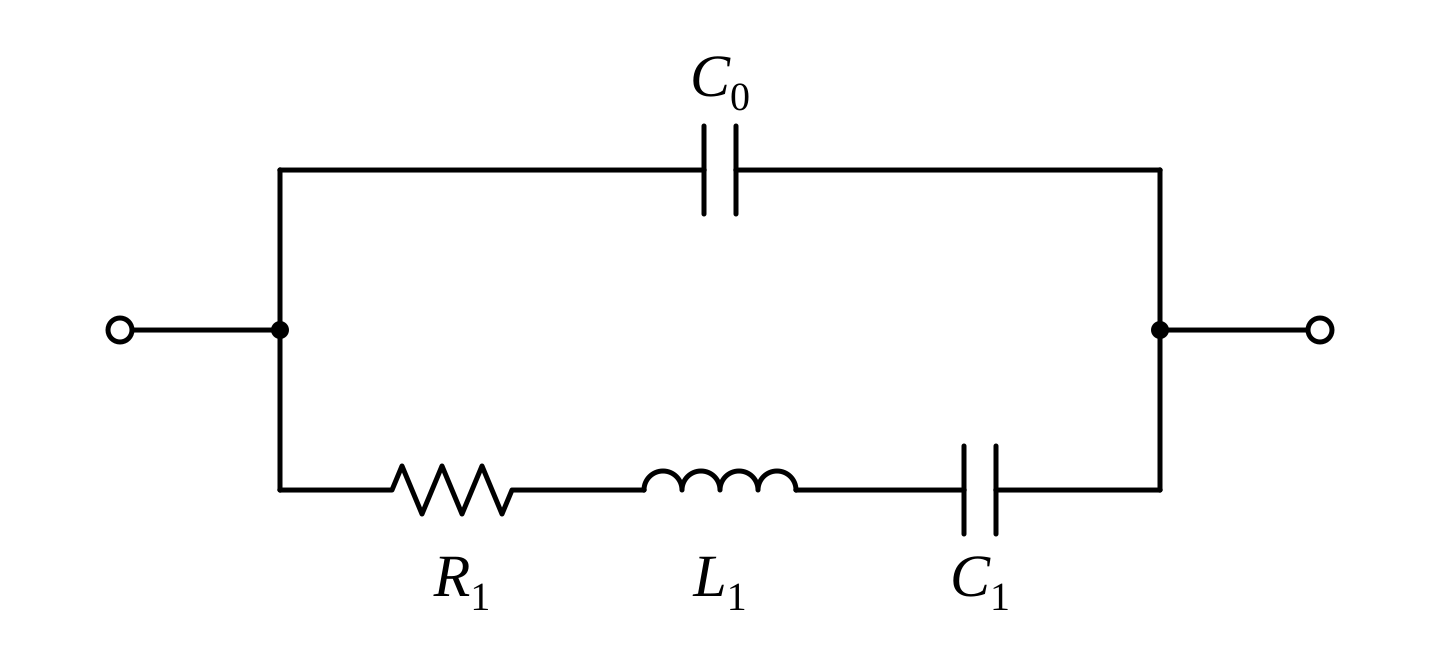

*Figure: BVD equivalent circuit, with $C_0$ in parallel with the series $R_1$–$L_1$–$C_1$ motional branch.*

## Impedance

With $Z_m = R_1 + sL_1 + \frac{1}{sC_1}$ in parallel with $\frac{1}{sC_0}$, the total impedance (as implemented in `Impedance.equivalent_impedance`) is

$$
Z(s) = \frac{C_1 L_1 s^2 + C_1 R_1 s + 1}{C_0 C_1 L_1 s^3 + C_0 C_1 R_1 s^2 + (C_0 + C_1)s}, \qquad s = j\omega .
$$

At low frequency $Z \to \dfrac{1}{s(C_0 + C_1)}$, so the actuator looks like a single capacitor $C_0 + C_1$ well below resonance.

## Initial estimates from the measured data

When an `Impedance` object is created, `resolve_resonance()` estimates the parameters directly from the sweep, using the admittance $Y = 1/Z = G + jB$:

- $f_R$ is the frequency of maximum conductance $G$, and $f_A$ is the frequency of maximum resistance $\operatorname{Re}(Z)$.
- At $f_R$ the motional branch is purely resistive, so $Y(\omega_R) = \dfrac{1}{R_1} + j\omega_R C_0$, which gives
$$
R_1 = \frac{1}{G_\text{max}}, \qquad C_0 = \frac{B(\omega_R)}{\omega_R} .
$$
- $Q_m = \dfrac{f_R}{f_2 - f_1}$, where $f_1$ and $f_2$ are the frequencies on either side of $f_R$ at which $G = G_\text{max}/2$.
- The motional capacitance and inductance follow from the two resonances:
$$
C_1 = C_0\left[\left(\frac{f_A}{f_R}\right)^2 - 1\right], \qquad L_1 = \frac{1}{\omega_R^2 C_1} .
$$

## Fitting

Both fit methods refine $(C_0, C_1, R_1, L_1)$ by fitting the model's real and imaginary parts of $Z$ to the measured ones at the same time, starting from the estimates above.

- **`curve_fit()`** uses `scipy.optimize.curve_fit` with every point weighted equally.
- **`least_squares_fit()`** uses `scipy.optimize.least_squares` with nonnegative bounds and a Gaussian weight centered on $f_R$:
$$
w(f) = 1 + (W - 1)\exp\!\left[-\frac{1}{2}\left(\frac{f - f_R}{\sigma}\right)^2\right], \qquad \sigma = \frac{f_A - f_R}{4} \text{ by default},
$$
where $W$ is `resonance_weight`. In this notebook the PI actuator uses $W = 100$, so the fit concentrates on the resonance region.
- **`off_res_cap`** constrains the low-frequency capacitance to $C_0 + C_1 = C_\text{off}$, which leaves only $C_0$, $R_1$ and $L_1$ to fit. With `off_res_cap=True` (used here for my actuator), $C_\text{off}$ is the mean of $\dfrac{1}{\omega |Z|}$ over the first 20 frequency points. A warning is issued if those points reach above $f_R/5$, because they may not be far enough from resonance. A float can be passed instead to set $C_\text{off}$ directly.

## Notes on the reported values

The fits update only $C_0$, $C_1$, $R_1$ and $L_1$. The values of $f_R$, $f_A$ and $Q_m$ printed by `summarize()`, and the dashed lines in the plot below, still come from the measured data. Values consistent with the fitted circuit can be computed from

$$
f_R = \frac{1}{2\pi\sqrt{L_1 C_1}}, \qquad Q_m = \frac{1}{R_1}\sqrt{\frac{L_1}{C_1}} .
$$

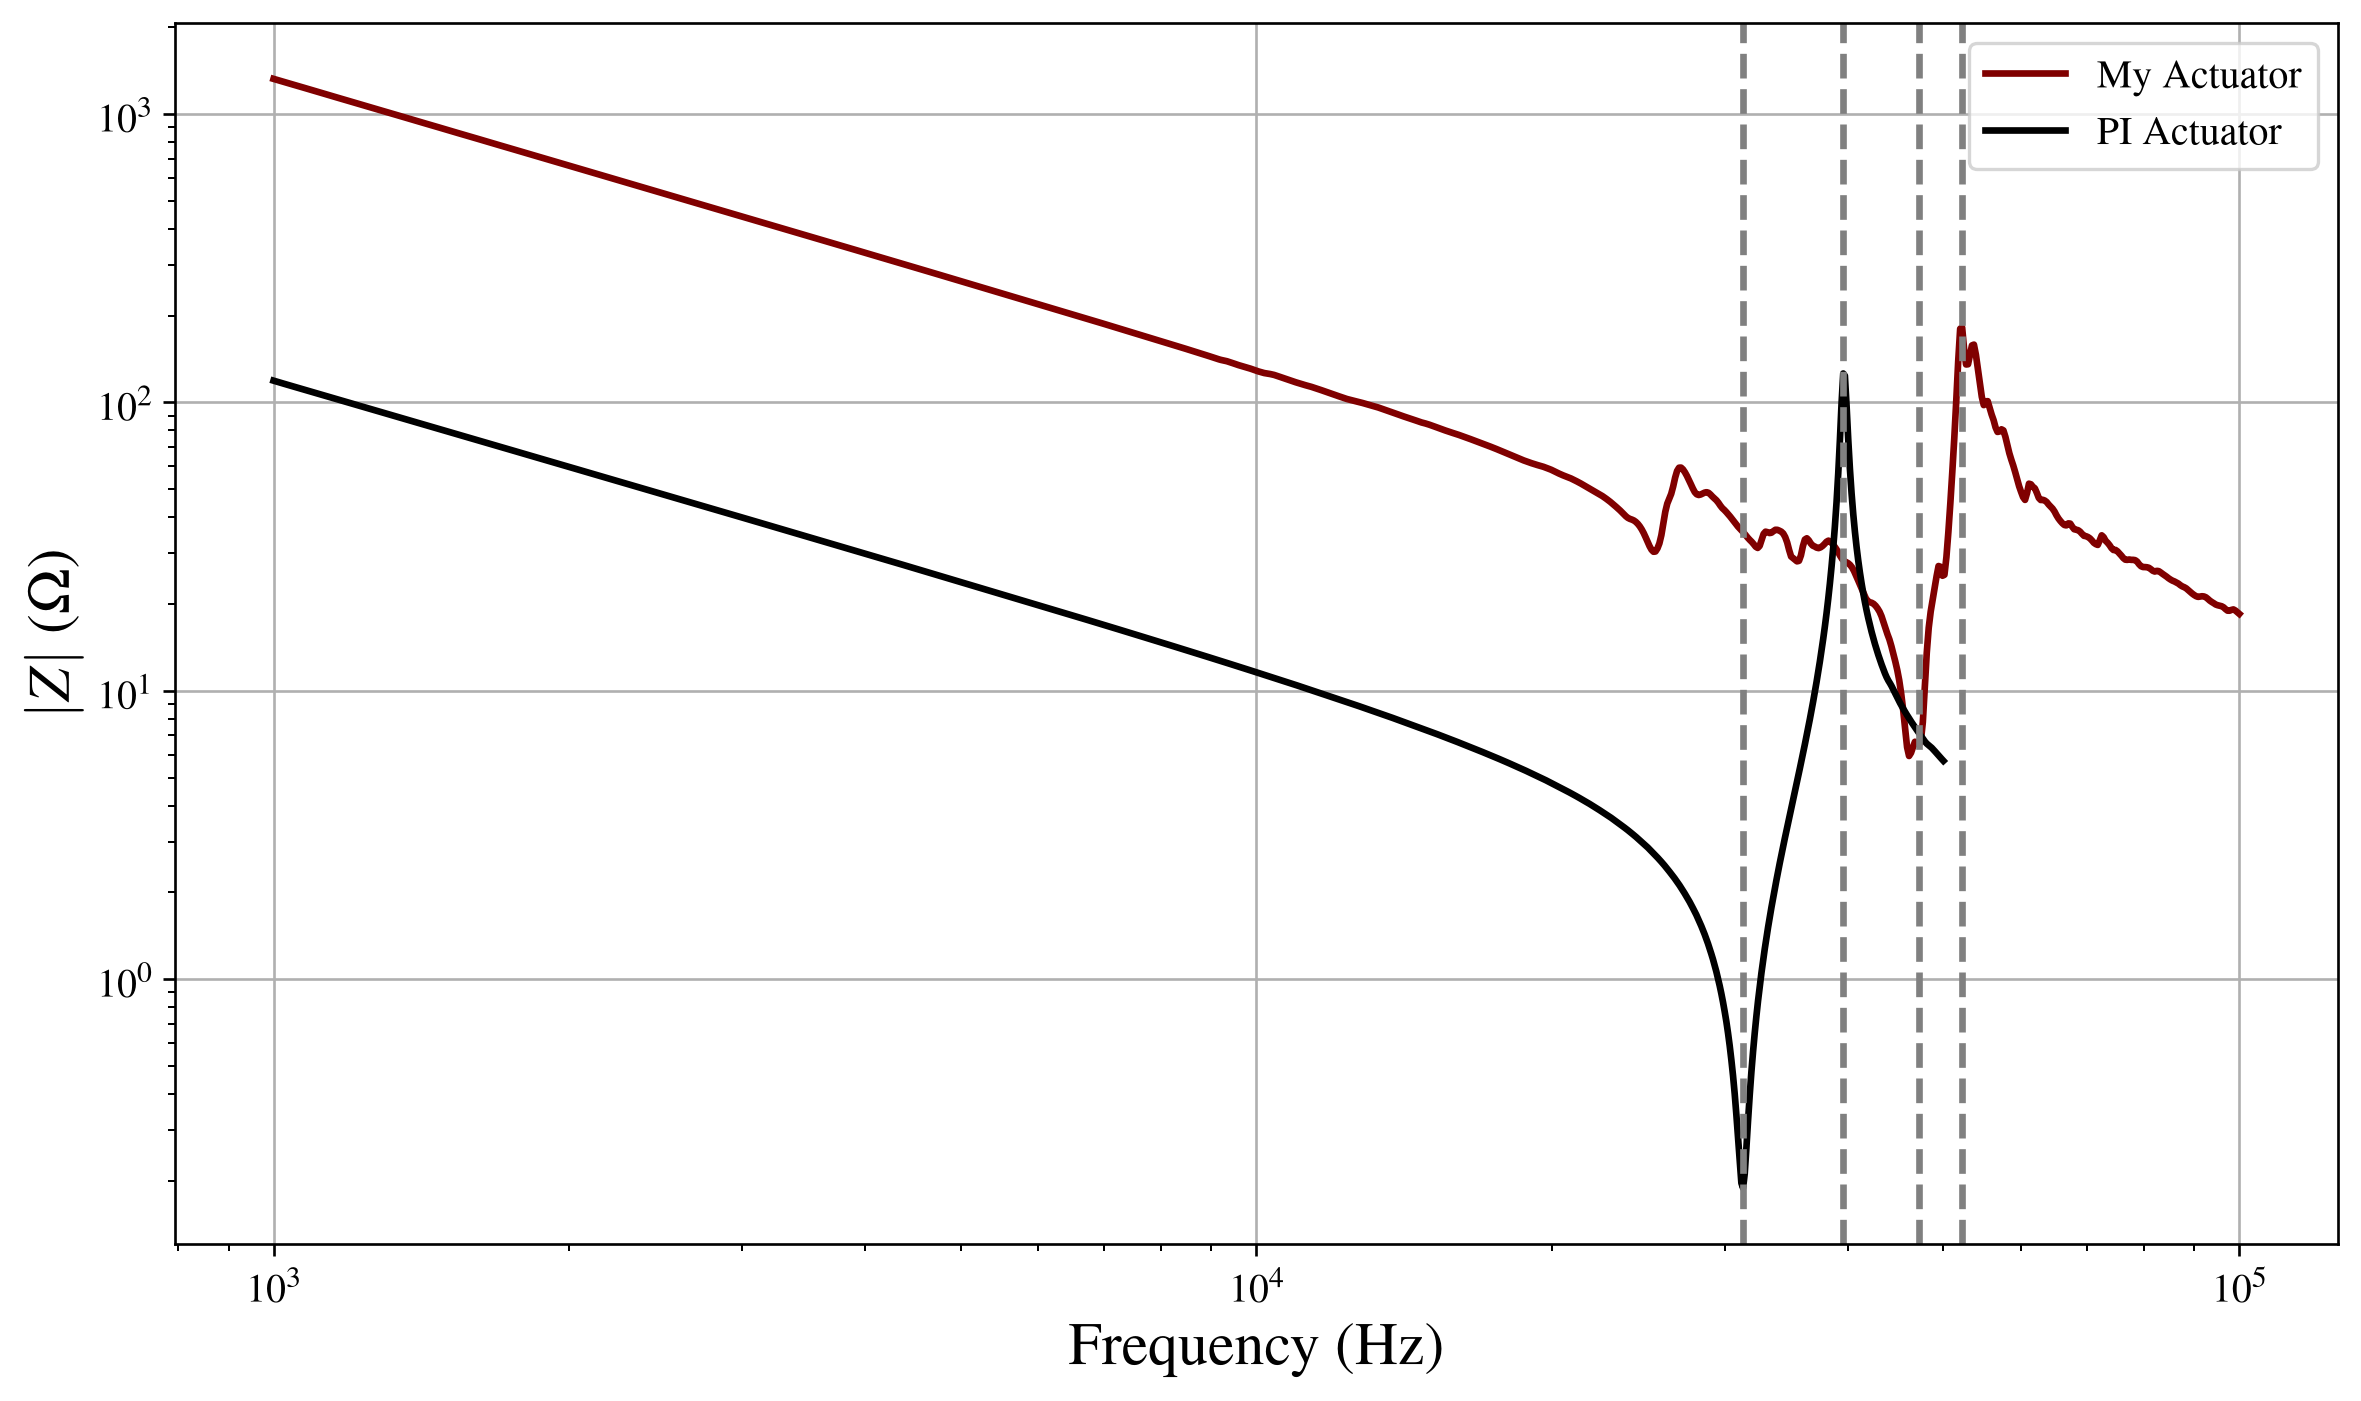

BVD Model Parameters:

            |------|| C0 ------|
            |                  |
---o--------|                  |--------o---
            |                  |
            |---R1---L1---C1---|

fR (Resonant Frequency): 47206.30 Hz
fA (Anti-Resonant Frequency): 52239.62 Hz
R1 (Motional Resistance): 6.89 Ω
C0 (Static Capacitance): 9.11e-08 F
Qm (Resonant Quality Factor): 23.73
C1 (Motional Capacitance): 2.90e-08 F
L1 (Motional Inductance): 4.10e-04 H

BVD Model Parameters:

            |------|| C0 ------|
            |                  |
---o--------|                  |--------o---
            |                  |
            |---R1---L1---C1---|

fR (Resonant Frequency): 31267.53 Hz
fA (Anti-Resonant Frequency): 39539.56 Hz
R1 (Motional Resistance): 0.18 Ω
C0 (Static Capacitance): 8.31e-07 F
Qm (Resonant Quality Factor): 52.19
C1 (Motional Capacitance): 5.04e-07 F
L1 (Motional Inductance): 5.15e-05 H


In [2]:
fig, ax = plt.subplots()
ax.set_xscale('log')
ax.set_yscale('log')

ax.plot(messy_obj.frequency, messy_obj.impedance_magnitude, label='My Actuator')
ax.plot(clean_obj.frequency, clean_obj.impedance_magnitude, label='PI Actuator')
ax.axvline(x=messy_obj.resonant_frequency, color='grey', ls='--')
ax.axvline(x=messy_obj.anti_resonant_frequency, color='grey', ls='--')
ax.axvline(x=clean_obj.resonant_frequency, color='grey', ls='--')
ax.axvline(x=clean_obj.anti_resonant_frequency, color='grey', ls='--')
# ax.plot(messy_obj.frequency, messy_parameter_response, ls='--')
# ax.plot(clean_obj.frequency, clean_parameter_response, ls='--')

ax.legend()
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel(r'$|Z|$ ($\Omega$)')

plt.show()

messy_obj.summarize()
print()
clean_obj.summarize()